
# Global Coffee Production: Correlation Analysis
### Coffee Production Trends | 1990/91–2019/20

## 1. Data Aggregation

Historical coffee production data are consolidated across 30 crop years to examine production patterns among four coffee classifications: Robusta, Arabica, Arabica/Robusta, and Robusta/Arabica.

Country-level observations are grouped by coffee classification, and annual production values are summed to calculate total production for each category and crop year.

An inconsistent classification label in the original dataset is standardized before aggregation. The original source file remains unchanged.

The resulting matrix contains four coffee classifications across 30 annual production periods.


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the coffee production dataset
df = pd.read_csv("Coffee_production.csv")

# Standardize the inconsistent classification
df["Coffee type"] = df["Coffee type"].replace({
    "Rocd Coffebusta/Arabica": "Robusta/Arabica"
})

# Select the 30 crop-year columns (1990/91–2019/20)
year_columns = df.columns[2:-1]

# Aggregate total production by coffee classification
production_by_type = (
    df.groupby("Coffee type")[year_columns]
    .sum()
)

# Arrange coffee classifications consistently
coffee_types = [
    "Robusta",
    "Arabica",
    "Arabica/Robusta",
    "Robusta/Arabica"
]

production_by_type = production_by_type.loc[coffee_types]

print("Annual Coffee Production by Classification")
display(production_by_type)


Annual Coffee Production by Classification


,1990/91,1991/92,1992/93,1993/94,1994/95,1995/96,1996/97,1997/98,1998/99,1999/00,...,2010/11,2011/12,2012/13,2013/14,2014/15,2015/16,2016/17,2017/18,2018/19,2019/20
Coffee type,,,,,,,,,,,,,,,,,,,,,
Robusta,2.664000e+08,3.548400e+08,2.288400e+08,1.988400e+08,2.697000e+08,2.283600e+08,3.907800e+08,3.269400e+08,2.577000e+08,4.851600e+08,...,1.627800e+08,2.485200e+08,2.121000e+08,2.532600e+08,1.984800e+08,1.719000e+08,1.532400e+08,1.859400e+08,2.148000e+08,2.001000e+08
Arabica,1.807140e+09,2.073960e+09,1.895580e+09,1.593720e+09,1.715940e+09,1.873440e+09,1.665720e+09,1.739400e+09,1.686780e+09,1.815000e+09,...,1.846080e+09,1.960020e+09,1.992300e+09,2.047680e+09,2.075280e+09,2.177340e+09,2.429880e+09,2.431260e+09,2.445300e+09,2.341020e+09
Arabica/Robusta,2.399820e+09,2.409960e+09,2.787060e+09,2.492700e+09,2.503560e+09,1.948140e+09,2.615880e+09,2.354940e+09,3.043860e+09,3.798120e+09,...,4.000620e+09,3.634680e+09,4.025820e+09,3.881640e+09,3.785460e+09,3.720480e+09,4.042620e+09,3.822840e+09,4.603500e+09,4.122780e+09
Robusta/Arabica,1.120440e+09,1.237380e+09,9.997800e+08,1.220280e+09,1.109640e+09,1.189320e+09,1.526280e+09,1.571940e+09,1.543620e+09,1.784760e+09,...,2.395020e+09,2.636400e+09,2.840820e+09,3.051960e+09,2.958720e+09,3.297840e+09,3.113340e+09,3.381540e+09,3.084180e+09,3.239280e+09



### Data Reshaping — Melt

The aggregated coffee production data are reshaped from wide to long format using the Pandas `melt()` method.

The transformation organizes coffee classifications, crop years, and production values into three columns.

The resulting dataset contains 120 observations representing four coffee classifications across 30 crop years. Production values remain unchanged, while the new structure supports comparison of annual production trends.


In [6]:
# Convert aggregated data from wide to long format
coffee_long = production_by_type.reset_index().melt(
    id_vars="Coffee type",
    value_vars=year_columns,
    var_name="Year",
    value_name="Production"
)

display(coffee_long.head(12))
print("Shape:", coffee_long.shape)

,Coffee type,Year,Production
0,Robusta,1990/91,2.664000e+08
1,Arabica,1990/91,1.807140e+09
2,Arabica/Robusta,1990/91,2.399820e+09
3,Robusta/Arabica,1990/91,1.120440e+09
4,Robusta,1991/92,3.548400e+08
5,Arabica,1991/92,2.073960e+09
6,Arabica/Robusta,1991/92,2.409960e+09
7,Robusta/Arabica,1991/92,1.237380e+09
8,Robusta,1992/93,2.288400e+08
9,Arabica,1992/93,1.895580e+09


Shape: (120, 3)



## 2. Data Transformation

The aggregated production matrix is transposed using the Pandas `.T` attribute.

This operation reorganizes the data so that each row represents a crop year and each column represents a coffee classification.

The transformed dataset contains 30 annual observations for each of the four coffee classifications, providing the appropriate structure for calculating correlations between production trends.


In [7]:

# Transpose the annual production matrix
production_transposed = production_by_type.T

# Display years as rows and coffee types as columns
print("Transposed Annual Coffee Production")
display(production_transposed)


Transposed Annual Coffee Production


Coffee type,Robusta,Arabica,Arabica/Robusta,Robusta/Arabica
1990/91,266400000.0,1.807140e+09,2.399820e+09,1.120440e+09
1991/92,354840000.0,2.073960e+09,2.409960e+09,1.237380e+09
1992/93,228840000.0,1.895580e+09,2.787060e+09,9.997800e+08
1993/94,198840000.0,1.593720e+09,2.492700e+09,1.220280e+09
1994/95,269700000.0,1.715940e+09,2.503560e+09,1.109640e+09
1995/96,228360000.0,1.873440e+09,1.948140e+09,1.189320e+09
1996/97,390780000.0,1.665720e+09,2.615880e+09,1.526280e+09
1997/98,326940000.0,1.739400e+09,2.354940e+09,1.571940e+09
1998/99,257700000.0,1.686780e+09,3.043860e+09,1.543620e+09
1999/00,485160000.0,1.815000e+09,3.798120e+09,1.784760e+09



## 3. Correlation Analysis

Pearson correlation coefficients are calculated to evaluate the strength and direction of linear relationships among the four coffee production classifications.

The coefficient ranges from -1 to +1, where positive values indicate that production volumes tend to move together, negative values indicate opposing movements, and values near zero indicate weak linear relationships.

The correlation matrix summarizes all pairwise relationships across the 30-year observation period. An annotated heatmap provides a visual comparison of the resulting coefficients.


Pearson Correlation Matrix


Coffee type,Robusta,Arabica,Arabica/Robusta,Robusta/Arabica
Coffee type,,,,
Robusta,1.000,-0.453,-0.313,-0.451
Arabica,-0.453,1.000,0.624,0.743
Arabica/Robusta,-0.313,0.624,1.000,0.826
Robusta/Arabica,-0.451,0.743,0.826,1.000


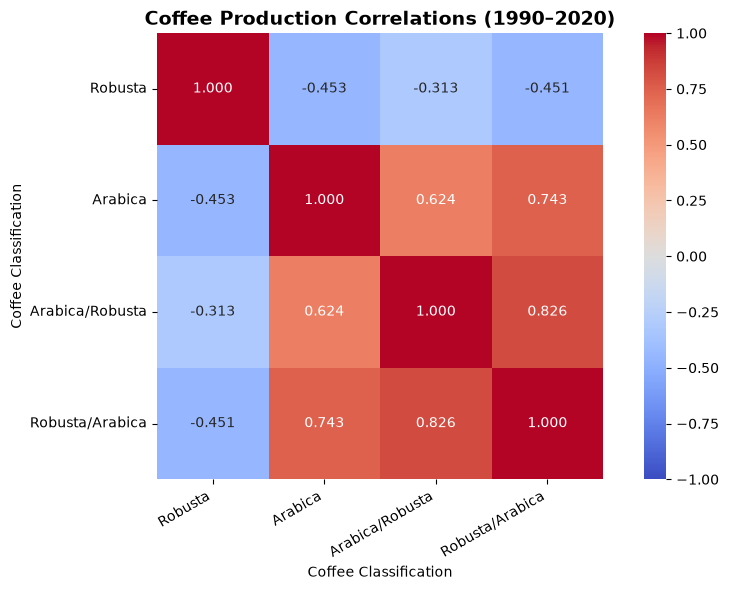

In [8]:

# Calculate the Pearson correlation matrix
correlation_matrix = production_transposed.corr(
    method="pearson"
)

print("Pearson Correlation Matrix")
display(correlation_matrix.round(3))

# Visualize the correlation coefficients
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title(
    "Coffee Production Correlations (1990–2020)",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Coffee Classification")
plt.ylabel("Coffee Classification")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [9]:

from itertools import combinations

# Compare each unique pair of coffee classifications
pairs = [
    (a, b, correlation_matrix.loc[a, b])
    for a, b in combinations(correlation_matrix.columns, 2)
]

# Identify the strongest positive relationship
strongest = max(pairs, key=lambda x: x[2])

# Identify the weakest relationship (closest to zero)
weakest = min(pairs, key=lambda x: abs(x[2]))

print("Strongest Positive Production Relationship")
print(f"Types: {strongest[0]} and {strongest[1]}")
print(f"Pearson coefficient: {strongest[2]:.4f}")

print("\nWeakest Production Relationship")
print(f"Types: {weakest[0]} and {weakest[1]}")
print(f"Pearson coefficient: {weakest[2]:.4f}")


Strongest Positive Production Relationship
Types: Arabica/Robusta and Robusta/Arabica
Pearson coefficient: 0.8263

Weakest Production Relationship
Types: Robusta and Arabica/Robusta
Pearson coefficient: -0.3127



## 4. Statistical Reflection

### 4.1 Strongest Positive Production Relationship

Coffee classifications: Arabica/Robusta and Robusta/Arabica
Pearson correlation coefficient: 0.8263

The strongest positive correlation indicates that these coffee classifications followed closely aligned production trends throughout the observation period.

This relationship may reflect shared agricultural expansion, increased cultivation capacity, or similar responses to international coffee demand. Improvements in farming technologies and infrastructure may also have contributed to parallel production growth.

Although a strong positive coefficient indicates statistical alignment, it does not establish a causal relationship between the two production classifications.

### 4.2 Weakest Production Relationship

**Coffee classifications:** [Insert weakest pair]  
**Pearson correlation coefficient:** [Insert coefficient]

The weakest correlation suggests that production volumes for these classifications followed comparatively independent trajectories over the 30-year period.

Differences in regional growing environments, temperature tolerances, rainfall variability, pest resistance, and agricultural infrastructure may help explain the limited relationship.

Geographic concentration and localized market conditions may also influence production patterns differently across coffee classifications.

These explanations are potential contributing factors rather than causal conclusions established by the correlation analysis.



## Machine Learning: Underfitting, Overfitting, and Generalization

### Training Error vs. Validation Error

Consider a predictive model trained on historical coffee production data from 1990/91 through 2019/20.

**Training error** measures how closely the model's predictions match actual production values in the data used for training.

**Validation error** measures the model's prediction accuracy on observations that were not used to update its weights.

For example, a model could be trained on crop years 1990/91–2014/15 and validated against 2015/16–2019/20. This chronological split would test whether patterns learned from earlier production records remain useful for predicting later years.

### Underfitting

Underfitting occurs when a model is too simple to capture important patterns in the data.

For example, **Robusta/Arabica** production increased from approximately **1.12 billion in 1990/91 to 3.24 billion in 2019/20**, representing growth of approximately **189%**.

A model that predicted nearly constant production throughout this period would fail to capture this substantial increase.

Such a model would likely exhibit high training and validation errors.

### Overfitting

Overfitting occurs when a model learns the training data too closely, including fluctuations that may not generalize to future observations.

For example, Robusta/Arabica production increased to approximately **3.30 billion in 2015/16**, decreased to **3.11 billion in 2016/17**, and increased again to **3.38 billion in 2017/18**.

An overly complex model might memorize these individual fluctuations rather than learning broader production patterns.

A common sign of overfitting is when training loss continues decreasing while validation loss begins increasing.

### Reducing Overfitting

Several approaches could improve the model's ability to generalize:

- **Regularization:** Apply L1 or L2 penalties to discourage unnecessary model complexity.
- **Early stopping:** Stop training when validation loss stops improving.
- **Model simplification:** Reduce unnecessary features or parameters.
- **Data quality:** Verify production measurements and classification consistency.
- **Chronological validation:** Train on earlier crop years and evaluate predictions on later years to prevent future data leakage.

### Interpretation

The coffee production dataset demonstrates why prediction accuracy must be evaluated beyond the training observations.

A model should capture meaningful long-term production patterns without memorizing every historical fluctuation.

The objective is to minimize prediction error on unseen observations and develop a model that generalizes to future production conditions.

*This discussion illustrates a hypothetical predictive model. The current analysis performs production aggregation and Pearson correlation analysis; no predictive machine learning model was trained.*


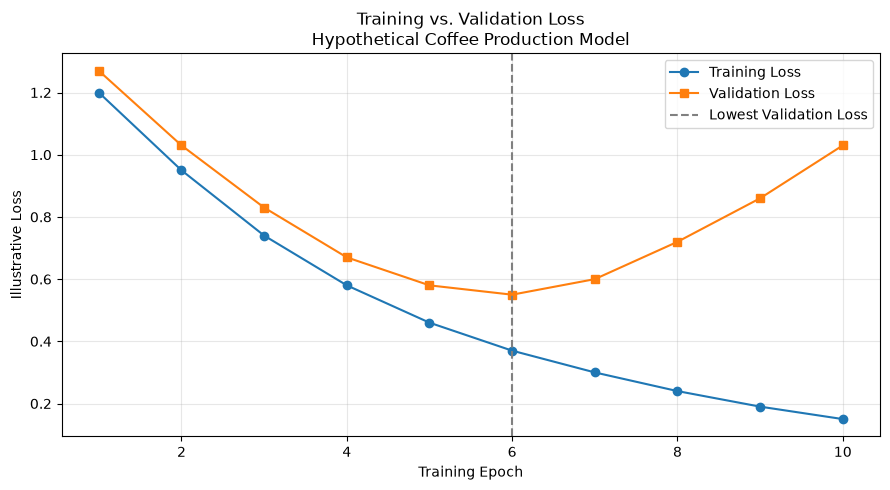

In [10]:

import matplotlib.pyplot as plt

# Illustrative loss values for a hypothetical coffee
# production prediction model — not actual training results
epochs = list(range(1, 11))

training_loss = [
    1.20, 0.95, 0.74, 0.58, 0.46,
    0.37, 0.30, 0.24, 0.19, 0.15
]

validation_loss = [
    1.27, 1.03, 0.83, 0.67, 0.58,
    0.55, 0.60, 0.72, 0.86, 1.03
]

plt.figure(figsize=(9, 5))

plt.plot(
    epochs, training_loss,
    marker="o", label="Training Loss"
)

plt.plot(
    epochs, validation_loss,
    marker="s", label="Validation Loss"
)

plt.axvline(
    x=6,
    linestyle="--",
    color="gray",
    label="Lowest Validation Loss"
)

plt.xlabel("Training Epoch")
plt.ylabel("Illustrative Loss")
plt.title(
    "Training vs. Validation Loss\n"
    "Hypothetical Coffee Production Model"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()



**Figure: Illustrative Training and Validation Loss**

This hypothetical learning curve demonstrates how overfitting can be detected by comparing training and validation error.

Training loss decreases throughout the training process, while validation loss reaches its minimum at epoch 6 before increasing.

The divergence suggests that continued training improves performance on the training data but reduces generalization to unseen observations.

Early stopping near epoch 6 could help prevent overfitting.

*Note: This visualization uses simulated loss values for educational purposes. No predictive model was trained on the coffee production dataset.*
